# WellSense · Notebook 2 — Knowledge Acquisition and Knowledge Base
This notebook presents the **knowledge base** of WellSense: where the knowledge came from, how it is represented, and checks that it is complete and consistent.

| Part | Contents |
|---|---|
| 1 | Knowledge sources and how knowledge was acquired |
| 2 | **Ontology** — wells, equipment, sensors, symptoms, faults, causes, actions, stakeholders (exported for Protégé) |
| 3 | Knowledge acquired **from data**: how each fault actually shows up in Petrobras's sensors |
| 4 | **Rule base** — 150+ production rules with certainty factors, organised in reasoning levels |
| 5 | Questions (backward chaining), maintenance actions, safety constraints, stakeholder profiles |
| 6 | Consistency checks |
| 7 | Loading the knowledge base into the SQLite database |

The knowledge lives in plain JSON files in `knowledge_base/`, **separate from the inference engine** (Notebook 3). Changing the knowledge never requires changing the engine — a core principle of knowledge-based systems.

## Setup

In [1]:
SOURCE = 'drive'          # 'drive' or 'upload' (see Notebook 1)

import os, sys, zipfile
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if not IN_COLAB:
    PROJECT_DIR = os.getcwd()
elif SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    # Find the WellSense folder, even if it ended up one level deeper (e.g. MyDrive/WellSense/WellSense)
    import glob
    _cands = ['/content/drive/MyDrive/WellSense'] + sorted(glob.glob('/content/drive/MyDrive/WellSense*')) \
             + sorted(glob.glob('/content/drive/MyDrive/*/WellSense*'))
    _cands += [c + '/WellSense' for c in list(_cands)]
    _found = [c for c in _cands if os.path.isfile(os.path.join(c, 'wellsense', '__init__.py'))]
    if not _found:
        raise FileNotFoundError("WellSense folder not found in My Drive. Upload the WHOLE unzipped WellSense folder "
                                "(it must contain the folders 'wellsense', 'data' and 'knowledge_base') to My Drive.")
    PROJECT_DIR = _found[0]
    print('Project folder:', PROJECT_DIR)
else:
    from google.colab import files
    PROJECT_DIR = '/content/WellSense'
    if not os.path.exists(PROJECT_DIR):
        for name in files.upload():
            zipfile.ZipFile(name).extractall('/content')
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
for d in ['outputs/figures', 'outputs/tables']:
    os.makedirs(d, exist_ok=True)

import json, sqlite3, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from wellsense import KnowledgeBase

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120); pd.set_option('display.max_rows', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

kb = KnowledgeBase('knowledge_base')
print(f'{len(kb.rules)} rules · {len(kb.faults)} faults · {len(kb.questions)} questions · '
      f'{len(kb.actions)} actions · {len(kb.constraints)} safety constraints · {len(kb.sources)} sources')

153 rules · 9 faults · 11 questions · 31 actions · 5 safety constraints · 10 sources


---
## 1. Knowledge sources and acquisition
Knowledge was acquired from **three kinds of sources**, and every rule, action and constraint cites at least one:

| Kind | Sources | What it contributed |
|---|---|---|
| **Expert / literature** | Vargas (2019) thesis; Vargas et al. (2025) 3W paper; PetroWiki (SPE); Schmidt et al. (1985); Godhavn et al. (2005); API RP 14B | What each fault is, how it shows in the sensors, its causes, corrective actions, safety rules, which sensors are reliable |
| **First principles** | Flow physics | *A blockage raises pressure upstream and lowers it downstream*; *stopped flow cools toward sea temperature* — used to locate the blockage along the flow path |
| **Data** | 125 development instances (Notebook 1) | Checking that each literature rule really holds in Petrobras's data; thresholds; revealing problems (e.g. the DHSV status signal) |

In [2]:
pd.DataFrame(kb.sources.values())[['id', 'type', 'citation']]

,id,type,citation
0,VARGAS2019,Doctoral thesis (expert knowledge),"Vargas, R.E.V. (2019). Base de dados e benchmarks para prognóstico de anomalias em sistemas de elevação de petróleo...."
1,VARGAS2025,Journal/preprint (dataset paper),"Vargas, R.E.V. et al. (2025). 3W Dataset 2.0.0: a realistic and public dataset with rare undesirable real events in ..."
2,PETROBRAS3W,Dataset documentation,"Petrobras (2024). 3W Project, dataset v2.0.0 — dataset.ini variable and event definitions. CC BY 4.0."
3,PETROWIKI_HYD,Engineering handbook (SPE PetroWiki),Society of Petroleum Engineers. Hydrate plug removal. PetroWiki (from the Petroleum Engineering Handbook).
4,SCHMIDT1985,Journal paper,"Schmidt, Z., Doty, D.R., Dutta-Roy, K. (1985). Severe slugging in offshore pipeline riser-pipe systems. SPE Journal ..."
5,GODHAVN2005,Journal paper,"Godhavn, J.-M., Fard, M.P., Fuchs, P.H. (2005). New slug control strategies, tuning rules and experimental results. ..."
6,API14B,Industry standard,"American Petroleum Institute. API RP 14B — Design, Installation, Operation, Test, and Redress of Subsurface Safety V..."
7,PHYSICS,First principles (flow physics),Basic flow physics: a restriction in a flow path raises pressure upstream of it and lowers pressure downstream of it...
8,DATA_DEV,Knowledge acquired from data (development set),"WellSense analysis of the 125 development instances (Notebook 2, Section 3): symptom frequencies after fault onset v..."
9,SHORTLIFFE1975,Journal paper (inference method),"Shortliffe, E.H., Buchanan, B.G. (1975). A model of inexact reasoning in medicine. Mathematical Biosciences 23(3–4),..."


In [3]:
uses = pd.Series([s for r in kb.rules for s in r.sources]).value_counts().rename('rules citing it')
uses.to_frame()

,rules citing it
DATA_DEV,74
VARGAS2019,50
VARGAS2025,32
PHYSICS,19
PETROWIKI_HYD,10
PETROBRAS3W,3
SCHMIDT1985,2


---
## 2. Ontology
The ontology defines **what exists** in the domain and **how things relate**. It is the vocabulary the rules are written in.

### 2.1 Equipment along the flow path
Oil flows from the reservoir up through the well to the platform. The order of equipment matters: it lets the KBS reason about **where** a blockage is.

In [4]:
eq = pd.DataFrame(kb.ontology['equipment'])
eq['on production path'] = eq['flow_position'].notna()
eq.sort_values('flow_position', na_position='last')[['id', 'label', 'flow_position', 'description']]

,id,label,flow_position,description
0,RESERVOIR,Reservoir,0.0,"Rock formation that supplies oil, gas and water"
1,PDG,Permanent downhole gauge,1.0,"Pressure/temperature gauge deep in the well, below the DHSV"
2,DHSV,Downhole safety valve,2.0,"Fail-safe valve in the production tubing, held open hydraulically"
3,TUBING,Production tubing,3.0,Pipe that carries fluid from the reservoir to the seabed
4,XMAS_TREE,Subsea Christmas tree (TPT),4.0,Valve assembly on the seabed; carries the TPT pressure/temperature transducer
5,PRODUCTION_LINE,Production line (flowline + riser),5.0,Pipe from the subsea tree up to the platform
6,PCK,Production choke (PCK),6.0,Topside valve that controls the well's flow
7,PLATFORM,Platform process plant,7.0,Separators and processing downstream of the choke
8,GLCK,Gas-lift choke (GLCK),NaN,Topside valve controlling gas-lift injection
9,SERVICE_LINE,Service line,NaN,Line from the platform to the well used for gas lift and operations


In [5]:
sensors = pd.DataFrame(kb.ontology['sensors'])
sensors

,tag,name,measures,located_at
0,P-PDG,p_pdg,pressure,PDG
1,T-PDG,t_pdg,temperature,PDG
2,P-TPT,p_tpt,pressure,XMAS_TREE
3,T-TPT,t_tpt,temperature,XMAS_TREE
4,P-MON-CKP,p_mon_ckp,pressure,PCK
5,T-JUS-CKP,t_jus_ckp,temperature,PCK
6,T-MON-CKP,t_mon_ckp,temperature,PCK
7,P-JUS-CKP,p_jus_ckp,pressure,PCK
8,ABER-CKP,aber_ckp,opening,PCK
9,P-JUS-CKGL,p_jus_ckgl,pressure,GLCK


### 2.2 Faults, causes and stakeholders

In [6]:
faults = pd.DataFrame(kb.faults).T[['code', 'label', 'category', 'severity', 'description']]
faults['cause'] = [', '.join(c['text'] for c in kb.ontology['causes'] if c['fault'] == f) for f in faults.index]
faults

,code,label,category,severity,description,cause
ABRUPT_INCREASE_OF_BSW,1,Abrupt increase of BSW,Reservoir / fluid,3,Sudden rise in the fraction of water and sediment in the produced liquid.,Water breakthrough (aquifer or injected water reaches the well)
SPURIOUS_CLOSURE_OF_DHSV,2,Spurious closure of DHSV,Equipment (safety valve),4,"The downhole safety valve closes by itself, usually without any surface indication; production stops.",DHSV or its hydraulic actuator fails and closes the valve with no surface command
SEVERE_SLUGGING,3,Severe slugging,Flow assurance,4,"Periodic, intense flow instability detectable along the whole production circuit; can stress or damage equipment.","Liquid accumulates at the riser base, then is pushed out by gas in cycles"
FLOW_INSTABILITY,4,Flow instability,Flow assurance,2,"Non-periodic, tolerable flow disturbances that can evolve into severe slugging.",Gas–liquid flow disturbances without a regular cycle
RAPID_PRODUCTIVITY_LOSS,5,Rapid productivity loss,Reservoir / fluid,3,System energy no longer overcomes losses; flow declines and natural flow can be lost.,"Reservoir properties change (pressure, BSW, GOR, viscosity) so energy no longer overcomes losses"
QUICK_RESTRICTION_IN_PCK,6,Quick restriction in PCK,Equipment (choke),2,"Fast, unwanted restriction of the production choke caused by operational problems.",Operational problem closes the production choke unintentionally
SCALING_IN_PCK,7,Scaling in PCK,Flow assurance,3,Inorganic deposits build up in the production choke and gradually restrict flow.,Inorganic deposits (scale) form in the choke
HYDRATE_IN_PRODUCTION_LINE,8,Hydrate in production line,Flow assurance,5,Ice-like water–gas crystals form at high pressure and low temperature and can block the production line.,Water and gas at high pressure and low temperature form hydrate crystals in the production line
HYDRATE_IN_SERVICE_LINE,9,Hydrate in service line,Flow assurance,4,Hydrate blockage in the service (gas-lift) line.,Water and gas at high pressure and low temperature form hydrate crystals in the service line


In [7]:
pd.DataFrame(kb.ontology['stakeholders'])

,id,role,concern
0,OPERATOR,Control-room operator,"Fast, clear alarms; few false alarms; simple steps"
1,PROD_ENG,Production engineer,Accurate diagnosis; keep the well producing
2,WELL_INTEGRITY,Well-integrity / maintenance team,Safe interventions; protect well barriers (DHSV)
3,HSE,HSE (safety) officer,"No unsafe recommendation, ever"
4,PROD_MANAGER,Production manager,Minimise lost production and downtime
5,FINANCE,Asset / finance manager,Minimise intervention cost (rigs can exceed US$500k/day)
6,RESERVOIR_ENG,Reservoir engineer,Understand water breakthrough and productivity changes


### 2.3 Ontology diagram
Production flow path (top), the sensor at each point, and the gas-lift path.

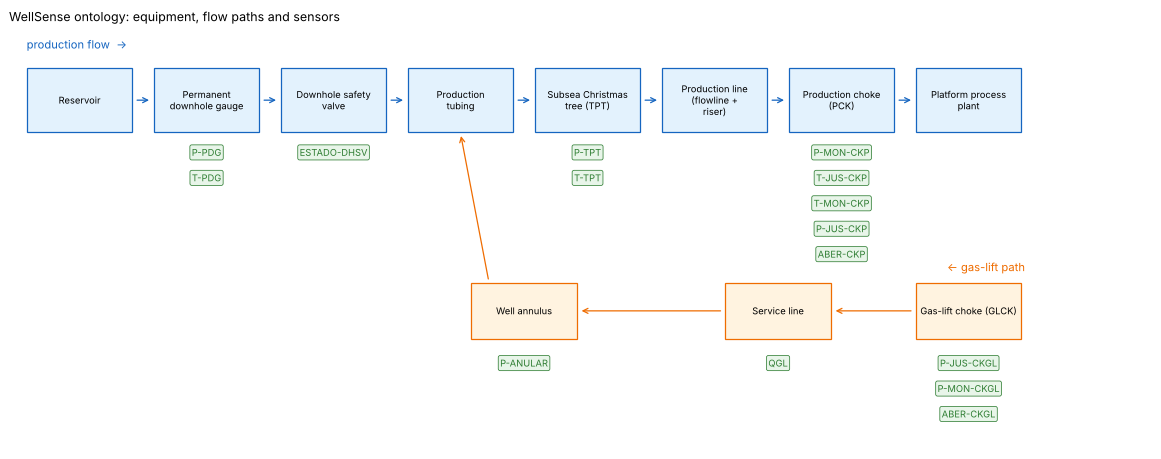

In [8]:
fig, ax = plt.subplots(figsize=(13, 5.2))
path = kb.ontology['relations']['upstreamOf (production path)']
lab = {e['id']: e['label'] for e in kb.ontology['equipment']}
xs = {e: i * 1.8 for i, e in enumerate(path)}
for e, x in xs.items():
    ax.add_patch(plt.Rectangle((x - 0.75, 2.6), 1.5, 0.8, fc='#e3f2fd', ec='#1565c0'))
    ax.text(x, 3.0, textwrap.fill(lab[e], 16), ha='center', va='center', fontsize=7.5)
for a, b in zip(path, path[1:]):
    ax.annotate('', xy=(xs[b] - 0.78, 3.0), xytext=(xs[a] + 0.78, 3.0), arrowprops=dict(arrowstyle='->', color='#1565c0'))
ax.text(xs[path[0]] - 0.75, 3.65, 'production flow  →', fontsize=9, color='#1565c0')
by_loc = sensors.groupby('located_at')['tag'].apply(list)
for e, tags in by_loc.items():
    if e in xs:
        for k, t in enumerate(tags):
            ax.text(xs[e], 2.3 - k * 0.32, t, ha='center', fontsize=7.5, color='#2e7d32',
                    bbox=dict(boxstyle='round,pad=0.2', fc='#e8f5e9', ec='#2e7d32', lw=0.6))
gl = kb.ontology['relations']['gas-lift path']
gx = {'GLCK': xs['PCK'] + 1.8, 'SERVICE_LINE': xs['PRODUCTION_LINE'] + 0.9, 'ANNULUS': xs['TUBING'] + 0.9}
for e, x in gx.items():
    ax.add_patch(plt.Rectangle((x - 0.75, 0.0), 1.5, 0.7, fc='#fff3e0', ec='#ef6c00'))
    ax.text(x, 0.35, lab[e], ha='center', va='center', fontsize=7.5)
    for k, t in enumerate(by_loc.get(e, [])):
        ax.text(x, -0.35 - k * 0.32, t, ha='center', fontsize=7.5, color='#2e7d32',
                bbox=dict(boxstyle='round,pad=0.2', fc='#e8f5e9', ec='#2e7d32', lw=0.6))
ax.annotate('', xy=(gx['SERVICE_LINE'] + 0.78, 0.35), xytext=(gx['GLCK'] - 0.78, 0.35), arrowprops=dict(arrowstyle='->', color='#ef6c00'))
ax.annotate('', xy=(gx['ANNULUS'] + 0.78, 0.35), xytext=(gx['SERVICE_LINE'] - 0.78, 0.35), arrowprops=dict(arrowstyle='->', color='#ef6c00'))
ax.annotate('', xy=(xs['TUBING'], 2.58), xytext=(gx['ANNULUS'] - 0.5, 0.72), arrowprops=dict(arrowstyle='->', color='#ef6c00'))
ax.text(gx['GLCK'] + 0.8, 0.85, '← gas-lift path', fontsize=9, color='#ef6c00', ha='right')
ax.set_xlim(-1, xs[path[-1]] + 2.6); ax.set_ylim(-1.4, 3.9); ax.axis('off')
ax.set_title('WellSense ontology: equipment, flow paths and sensors', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/10_ontology_flow_path.png', dpi=150); plt.show()

### 2.4 Export to OWL (Turtle) for Protégé
The ontology and rules are also written as an OWL/RDF file (`knowledge_base/wellsense_ontology.ttl`). Open it in **Protégé** (free, from Stanford) to browse classes, individuals and relations.

In [9]:
def iri(x):
    return 'ws:' + ''.join(ch if ch.isalnum() else '_' for ch in str(x))

def lit(x):
    return '"' + str(x).replace('\\', '\\\\').replace('"', '\\"') + '"'

T = ['@prefix ws: <http://wellsense.example.org/ontology#> .',
     '@prefix owl: <http://www.w3.org/2002/07/owl#> .',
     '@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .',
     '@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .', '']
classes = ['Equipment', 'Sensor', 'Symptom', 'Fault', 'Cause', 'MaintenanceAction', 'SafetyConstraint',
           'Stakeholder', 'KnowledgeSource', 'Rule', 'Question']
for c in classes:
    T.append(f'ws:{c} a owl:Class .')
for p, dom, rng in [('upstreamOf', 'Equipment', 'Equipment'), ('locatedAt', 'Sensor', 'Equipment'),
                    ('causedBy', 'Fault', 'Cause'), ('mitigatedBy', 'Fault', 'MaintenanceAction'),
                    ('violates', 'MaintenanceAction', 'SafetyConstraint'), ('concludes', 'Rule', 'Fault'),
                    ('citesSource', 'Rule', 'KnowledgeSource'), ('asksAbout', 'Question', 'Fault')]:
    T.append(f'ws:{p} a owl:ObjectProperty ; rdfs:domain ws:{dom} ; rdfs:range ws:{rng} .')
for p in ['certaintyFactor', 'condition', 'explanation', 'severity', 'safetyRisk', 'cost', 'effectiveness', 'productionLoss']:
    T.append(f'ws:{p} a owl:DatatypeProperty .')
T.append('')
for e in kb.ontology['equipment']:
    T.append(f"{iri(e['id'])} a ws:Equipment ; rdfs:label {lit(e['label'])} ; rdfs:comment {lit(e['description'])} .")
for a, b in zip(path, path[1:]):
    T.append(f'{iri(a)} ws:upstreamOf {iri(b)} .')
for s in kb.ontology['sensors']:
    T.append(f"{iri(s['tag'])} a ws:Sensor ; rdfs:label {lit(s['tag'])} ; ws:locatedAt {iri(s['located_at'])} .")
for f, d in kb.faults.items():
    T.append(f"{iri(f)} a ws:Fault ; rdfs:label {lit(d['label'])} ; ws:severity {d['severity']} ; rdfs:comment {lit(d['description'])} .")
for c in kb.ontology['causes']:
    T.append(f"{iri(c['id'])} a ws:Cause ; rdfs:label {lit(c['text'])} .")
    T.append(f"{iri(c['fault'])} ws:causedBy {iri(c['id'])} .")
for k in kb.constraints.values():
    T.append(f"{iri(k['id'])} a ws:SafetyConstraint ; rdfs:label {lit(k['text'])} .")
for a in kb.actions:
    T.append(f"{iri(a['id'])} a ws:MaintenanceAction ; rdfs:label {lit(a['text'])} ; ws:safetyRisk {a['safety_risk']} ; "
             f"ws:productionLoss {a['production_loss']} ; ws:cost {a['cost']} ; ws:effectiveness {a['effectiveness']} .")
    if a['fault'] in kb.faults:
        T.append(f"{iri(a['fault'])} ws:mitigatedBy {iri(a['id'])} .")
    if a['violates']:
        T.append(f"{iri(a['id'])} ws:violates {iri(a['violates'])} .")
for s in kb.ontology['stakeholders']:
    T.append(f"{iri(s['id'])} a ws:Stakeholder ; rdfs:label {lit(s['role'])} ; rdfs:comment {lit(s['concern'])} .")
for s in kb.sources.values():
    T.append(f"{iri(s['id'])} a ws:KnowledgeSource ; rdfs:label {lit(s['citation'])} .")
for q in kb.questions.values():
    T.append(f"{iri(q['id'])} a ws:Question ; rdfs:label {lit(q['text'])} ; "
             + ' ; '.join(f'ws:asksAbout {iri(f)}' for f in q['about']) + ' .')
for r in kb.rules:
    line = (f"{iri('rule_' + r.id)} a ws:Rule ; rdfs:label {lit(r.name)} ; ws:condition {lit(' AND '.join(str(c) for c in r.conditions))} ; "
            f"ws:certaintyFactor {r.cf} ; ws:explanation {lit(r.explanation)}")
    if r.fact == 'FAULT':
        line += f' ; ws:concludes {iri(r.value)}'
    line += ''.join(f' ; ws:citesSource {iri(s)}' for s in r.sources) + ' .'
    T.append(line)
with open('knowledge_base/wellsense_ontology.ttl', 'w', encoding='utf-8') as f:
    f.write('\n'.join(T))
print(f'Wrote knowledge_base/wellsense_ontology.ttl ({len(T)} statements)')

Wrote knowledge_base/wellsense_ontology.ttl (344 statements)


---
## 3. Knowledge acquired from data
Before writing rules, each literature description was checked against the development data: **how often does a symptom appear after the fault starts, compared with normal operation?**
A big difference (e.g. 90% vs 1%) means the symptom is a reliable sign of that fault.

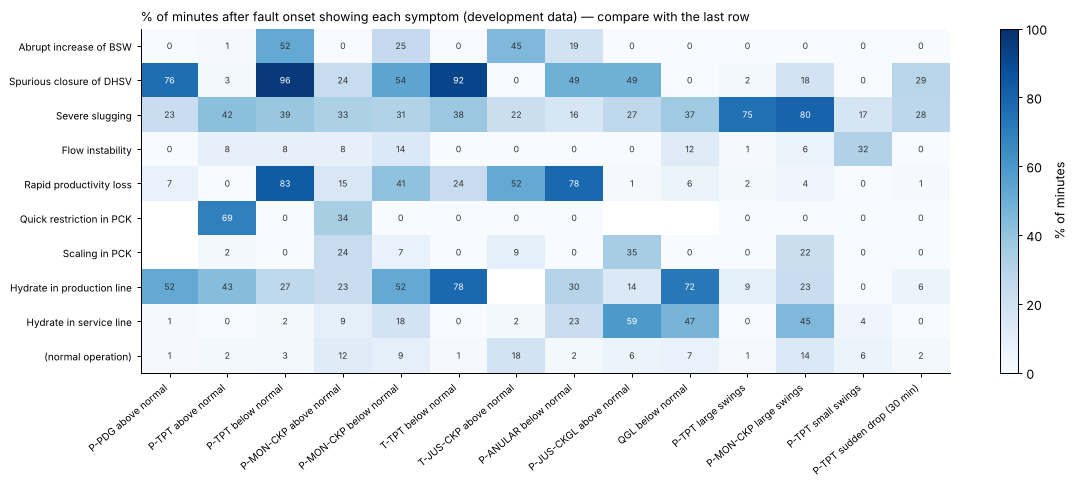

In [10]:
con = sqlite3.connect('db/wellsense.db')
facts = pd.read_sql('SELECT * FROM facts', con)
CHECKS = [('P-PDG above normal', 'p_pdg_level', 'HIGH'), ('P-TPT above normal', 'p_tpt_level', 'HIGH'),
          ('P-TPT below normal', 'p_tpt_level', 'LOW'), ('P-MON-CKP above normal', 'p_mon_ckp_level', 'HIGH'),
          ('P-MON-CKP below normal', 'p_mon_ckp_level', 'LOW'), ('T-TPT below normal', 't_tpt_level', 'LOW'),
          ('T-JUS-CKP above normal', 't_jus_ckp_level', 'HIGH'), ('P-ANULAR below normal', 'p_anular_level', 'LOW'),
          ('P-JUS-CKGL above normal', 'p_jus_ckgl_level', 'HIGH'), ('QGL below normal', 'qgl_level', 'LOW'),
          ('P-TPT large swings', 'p_tpt_cycle', 'LARGE'), ('P-MON-CKP large swings', 'p_mon_ckp_cycle', 'LARGE'),
          ('P-TPT small swings', 'p_tpt_cycle', 'SMALL'), ('P-TPT sudden drop (30 min)', 'p_tpt_jump30', 'JUMP_DOWN')]
normal_ref = facts[facts.phase == 'normal']
rows = {}
for name in kb.faults:
    post = facts[(facts.event_name == name) & facts.phase.isin(['transient', 'steady'])]
    rows[kb.faults[name]['label']] = [round((post[c][post[c] != 'UNKNOWN'] == v).mean() * 100) if (post[c] != 'UNKNOWN').any() else np.nan
                                     for _, c, v in CHECKS]
rows['(normal operation)'] = [round((normal_ref[c][normal_ref[c] != 'UNKNOWN'] == v).mean() * 100) for _, c, v in CHECKS]
evidence = pd.DataFrame(rows, index=[n for n, _, _ in CHECKS]).T
evidence.to_csv('outputs/tables/kb_data_evidence.csv')

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(evidence.values, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(evidence.shape[1]), evidence.columns, rotation=40, ha='right', fontsize=8)
ax.set_yticks(range(evidence.shape[0]), evidence.index, fontsize=8)
for i in range(evidence.shape[0]):
    for j in range(evidence.shape[1]):
        v = evidence.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color='white' if v > 55 else '#333')
ax.set_title('% of minutes after fault onset showing each symptom (development data) — compare with the last row', loc='left', fontsize=10)
fig.colorbar(im, ax=ax, label='% of minutes')
plt.tight_layout(); plt.savefig('outputs/figures/11_symptom_evidence.png', dpi=150); plt.show()

**What the data confirmed** (each matches the literature and became rules):
* **Spurious DHSV closure:** pressure below the valve (PDG) up, above it (TPT) down, subsea temperature down (flow stopped) — Vargas 2025 Fig. 3.
* **Severe slugging:** large repeated swings at TPT and before the choke (> 10 bar) — Vargas 2025 Fig. 6.
* **Quick restriction in PCK:** TPT pressure up — Vargas 2025 Fig. 4.
* **Hydrate in production line:** PDG and TPT up, subsea temperature down — Vargas 2025 Fig. 5; Vargas 2019 Sec. 2.3.8.
* **Rapid productivity loss:** pressures fall across the system, including the annulus.
* **Hydrate in service line:** gas-lift pressure up, gas-lift flow down.

**What the data contradicted** (knowledge refinement — see Notebook 3): the DHSV *status signal* almost never shows the valve closed during real spurious closures (14 of ~1,500 minutes) but often shows "closed" during normal operation. This agrees with the thesis ("usually without any surface indication"), so rules using that signal were removed.

---
## 4. Rule base
Knowledge is represented as **production rules** (IF conditions THEN conclusion) with **certainty factors** (MYCIN, Shortliffe & Buchanan 1975), organised in reasoning levels. Lower levels feed higher ones, so the engine builds a **chain of reasoning** from raw sensor facts to a diagnosis:

| Level | Example | Salience |
|---|---|---|
| Sensor fact → symptom | IF `p_tpt.level = LOW` THEN `TPT_P = DOWN` | 90 |
| Context | IF `well_state = Shut-In` THEN `OPERATION = SHUT_IN` | 85 |
| Sensor validation | IF `p_pdg.quality = FROZEN` AND `TPT_P` changing THEN alert: PDG frozen | 80 |
| Combined symptom | IF `TPT_T = DOWN` THEN `FLOW = STOPPING` | 70 |
| **Restriction location** | IF `PDG_P = UP` AND `TPT_P = DOWN` THEN `RESTRICTION = DHSV_ZONE` | 60 |
| **Diagnosis** | IF `RESTRICTION = DHSV_ZONE` AND `FLOW = STOPPING` THEN DHSV closure (CF 0.85) | 40 |
| Operator answer | IF suspect DHSV AND operator says "not commanded" THEN DHSV +0.5 | 35 |
| Meta (context) | IF an operation is in progress THEN discount faults it explains | 30 |

Salience is used for **conflict resolution** (Notebook 3): higher-level evidence is always settled before conclusions that depend on it.

In [11]:
rules = pd.DataFrame([{'id': r.id, 'level': r.level, 'salience': r.salience, 'IF': ' AND '.join(str(c) for c in r.conditions),
                       'THEN': f'{r.fact} = {r.value}', 'CF': r.cf, 'sources': ', '.join(r.sources), 'name': r.name}
                      for r in kb.rules])
summary = rules.groupby(['salience', 'level']).size().rename('rules').reset_index().sort_values('salience', ascending=False)
summary

,salience,level,rules
7,90,symptom,63
6,85,context,4
5,80,sensor,3
4,70,symptom,8
3,60,location,9
2,40,diagnosis,35
1,35,answer,21
0,30,meta,10


### The diagnosis rules (level "diagnosis")

In [12]:
rules[rules.level == 'diagnosis'][['id', 'IF', 'THEN', 'CF', 'sources']]

,id,IF,THEN,CF,sources
87,D-DHSV-1,RESTRICTION = DHSV_ZONE AND FLOW = STOPPING,FAULT = SPURIOUS_CLOSURE_OF_DHSV,0.85,"VARGAS2019, VARGAS2025"
88,D-DHSV-2,RESTRICTION = DHSV_ZONE,FAULT = SPURIOUS_CLOSURE_OF_DHSV,0.60,VARGAS2025
89,D-DHSV-N,TEMPS = UP,FAULT = SPURIOUS_CLOSURE_OF_DHSV,-0.40,PHYSICS
90,D-BSW-1,NOT OSC_FLOW = YES AND TPT_P = DOWN AND TEMPS = UP,FAULT = ABRUPT_INCREASE_OF_BSW,0.70,VARGAS2019
91,D-BSW-2,NOT OSC_FLOW = YES AND PDG_P = UP AND TPT_P = DOWN AND TEMPS = UP,FAULT = ABRUPT_INCREASE_OF_BSW,0.80,VARGAS2019
92,D-BSW-3,NOT OSC_FLOW = YES AND TPT_P = DOWN AND CKP_P = DOWN AND NOT FLOW = STOPPING AND NOT TPT_JUMP = DOWN AND NOT ANN_P =...,FAULT = ABRUPT_INCREASE_OF_BSW,0.45,"VARGAS2019, DATA_DEV"
93,D-BSW-N,FLOW = STOPPING,FAULT = ABRUPT_INCREASE_OF_BSW,-0.50,VARGAS2019
94,D-SLUG-1,TPT_CYCLE = LARGE AND CKP_CYCLE = LARGE,FAULT = SEVERE_SLUGGING,0.90,"VARGAS2019, VARGAS2025, SCHMIDT1985"
95,D-SLUG-2,TPT_CYCLE = LARGE,FAULT = SEVERE_SLUGGING,0.70,VARGAS2025
96,D-SLUG-3,CKP_CYCLE = LARGE AND TPT_T_CYCLE = LARGE,FAULT = SEVERE_SLUGGING,0.70,"VARGAS2019, DATA_DEV"


### Restriction-location and sensor-validation rules

In [13]:
rules[rules.level.isin(['location', 'sensor', 'context'])][['id', 'IF', 'THEN', 'CF', 'sources']]

,id,IF,THEN,CF,sources
63,X-SHUTIN,well_state = Shut-In/Closed With Diesel/Closed With Gas,OPERATION = SHUT_IN,1.00,VARGAS2025
64,X-RESTART,well_state = Restart,OPERATION = RESTART,1.00,VARGAS2025
65,X-INTERV,well_state = Flushing Diesel/Flushing Gas/Bullheading/Depressurization,OPERATION = INTERVENTION,1.00,VARGAS2025
66,X-COVERAGE,DATA_COVERAGE = LOW,STATUS = INSUFFICIENT_DATA,1.00,VARGAS2019
67,V-PDG-FROZEN,p_pdg.quality = FROZEN AND TPT_P = UP/DOWN,SENSOR_ALERT = PDG_FROZEN,1.00,VARGAS2019
68,V-PDG-FAIL,p_pdg.quality = INVALID,SENSOR_ALERT = PDG_FAILED,1.00,VARGAS2019
69,V-TPT-FROZEN,p_tpt.quality = FROZEN,SENSOR_ALERT = TPT_FROZEN,1.00,VARGAS2019
78,L-DHSV-1,NOT OSC_FLOW = YES AND PDG_P = UP AND TPT_P = DOWN,RESTRICTION = DHSV_ZONE,0.90,"PHYSICS, VARGAS2025"
79,L-DHSV-2,NOT OSC_FLOW = YES AND TPT_P = DOWN AND CKP_P = DOWN AND TPT_JUMP = DOWN AND NOT PDG_P = UP,RESTRICTION = DHSV_ZONE,0.60,"PHYSICS, VARGAS2025"
80,L-DHSV-3,NOT OSC_FLOW = YES AND TPT_P = DOWN AND TPT_JUMP = DOWN AND FLOW = STOPPING AND NOT PDG_P = UP AND NOT CKP_P = UP,RESTRICTION = DHSV_ZONE,0.55,"PHYSICS, VARGAS2019"


### The reasoning network
How intermediate conclusions connect to the faults (edges = diagnosis rules with positive CF). Blue = intermediate symptoms/locations, red = faults.

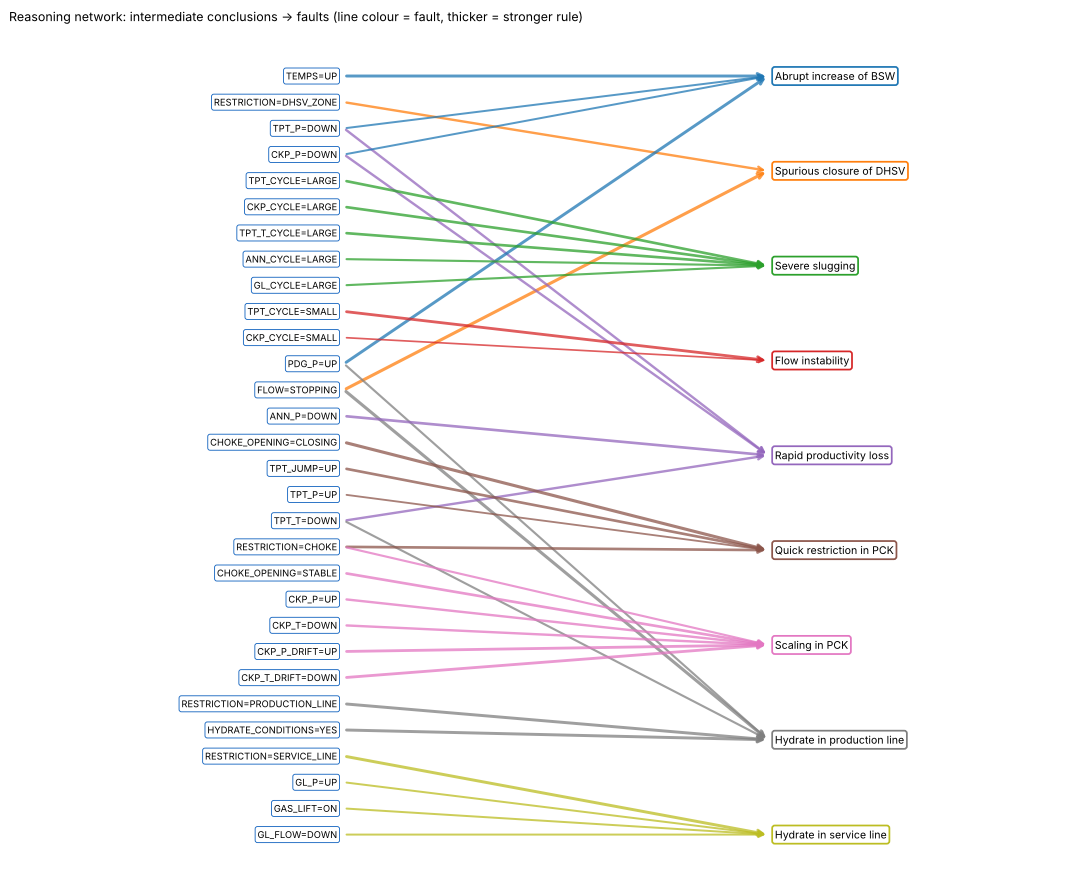

In [14]:
G = nx.DiGraph()
for r in kb.rules:
    if r.level == 'diagnosis' and r.cf > 0:
        for c in r.conditions:
            if not c.negated and c.fact == c.fact.upper():
                for v in c.values:
                    G.add_edge(f'{c.fact}={v}', kb.faults[r.value]['label'], weight=r.cf)
right = [kb.faults[f]['label'] for f in kb.faults]
ry = {n: -i * 2.0 for i, n in enumerate(right)}
# place each intermediate node next to the faults it supports (fewer crossing lines)
left = sorted([n for n in G if '=' in n], key=lambda n: np.mean([ry[t] for t in G.successors(n)]), reverse=True)
pos = {n: (0, -i * (2.0 * (len(right) - 1)) / max(len(left) - 1, 1)) for i, n in enumerate(left)}
pos.update({n: (3.2, y) for n, y in ry.items()})
palette = plt.cm.tab10.colors
col = {n: palette[i % 10] for i, n in enumerate(right)}
fig, ax = plt.subplots(figsize=(12, 10))
for u, v in G.edges():
    ax.annotate('', xy=(pos[v][0] - 0.05, pos[v][1]), xytext=(pos[u][0] + 0.05, pos[u][1]),
                arrowprops=dict(arrowstyle='->', color=col[v], lw=0.6 + 2.2 * G[u][v]['weight'], alpha=0.75))
for n, (x, y) in pos.items():
    is_fault = '=' not in n
    ax.text(x, y, n, ha='left' if is_fault else 'right', va='center', fontsize=8.5 if is_fault else 7.5,
            bbox=dict(boxstyle='round,pad=0.25', fc='#ffffff', ec=col[n] if is_fault else '#1565c0', lw=1.4 if is_fault else 0.7))
ax.set_xlim(-2.4, 5.3); ax.set_ylim(min(ry.values()) - 1, 1); ax.axis('off')
ax.set_title('Reasoning network: intermediate conclusions → faults (line colour = fault, thicker = stronger rule)', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/12_reasoning_network.png', dpi=150); plt.show()

---
## 5. Questions, maintenance actions, safety constraints and stakeholder profiles
### 5.1 Questions for backward chaining
Some evidence cannot come from sensors — only a person can check it. When the KBS is unsure, it asks the most useful of these questions (Notebook 3).

In [15]:
pd.DataFrame(kb.questions.values())[['id', 'text', 'who', 'about']]

,id,text,who,about
0,Q_DHSV_COMMANDED,Was the DHSV closed on purpose (shutdown or ESD command) in the last hour?,Control-room operator,[SPURIOUS_CLOSURE_OF_DHSV]
1,Q_DHSV_HYDRAULICS,Is the DHSV hydraulic control-line pressure at its normal value?,Control-room operator,[SPURIOUS_CLOSURE_OF_DHSV]
2,Q_WATER_SAMPLE,Does the latest fluid sample show a higher water cut (BSW) than before?,Production chemist,[ABRUPT_INCREASE_OF_BSW]
3,Q_SEPARATOR_SURGES,"Are the platform separator levels surging in a regular, repeating cycle?",Control-room operator,"[SEVERE_SLUGGING, FLOW_INSTABILITY]"
4,Q_SETPOINT_CHANGE,Was the production choke or gas-lift rate changed in the last 2 hours?,Control-room operator,"[FLOW_INSTABILITY, QUICK_RESTRICTION_IN_PCK]"
5,Q_WELL_TEST,Did the most recent well test show production below the expected rate?,Production engineer,[RAPID_PRODUCTIVITY_LOSS]
6,Q_CHOKE_LOCAL,"Checked on site, is the production choke more closed than its set-point?",Field operator,"[QUICK_RESTRICTION_IN_PCK, SCALING_IN_PCK]"
7,Q_SCALE_HISTORY,"Has this well had scale deposits before, or does water analysis show a scaling tendency?",Production chemist,[SCALING_IN_PCK]
8,Q_HYDRATE_CURVE,Is the production line inside the hydrate-formation region for its current pressure and temperature?,Flow-assurance engineer,"[HYDRATE_IN_PRODUCTION_LINE, HYDRATE_IN_SERVICE_LINE]"
9,Q_RECENT_RESTART,Was the well shut in or restarted during the last 24 hours?,Control-room operator,"[HYDRATE_IN_PRODUCTION_LINE, HYDRATE_IN_SERVICE_LINE]"


### 5.2 Safety constraints (hard rules — can never be overridden)

In [16]:
pd.DataFrame(kb.constraints.values())[['id', 'text', 'sources']]

,id,text,sources
0,SC-HYD-ONESIDE,Never depressurize a hydrate plug from one side only — a pressure difference across a released plug turns it into a ...,[PETROWIKI_HYD]
1,SC-HYD-HEAT,Never heat the middle of a hydrate plug — released gas can be trapped and rupture the pipe.,[PETROWIKI_HYD]
2,SC-DHSV-EQUALIZE,"Never force a closed DHSV open against a pressure difference — equalize pressure across the valve first, then reopen...",[API14B]
3,SC-SLUG-IGNORE,Do not keep producing through sustained severe slugging without mitigation — it stresses and can damage well and pla...,"[VARGAS2019, SCHMIDT1985]"
4,SC-SENSOR,Do not base a well-integrity decision on a sensor flagged as frozen or failed.,[VARGAS2019]


### 5.3 Maintenance actions
Each action is scored 1–5 on four criteria that reflect different stakeholders: **safety risk** (HSE), **production loss** (production manager), **cost** (finance) and **effectiveness** (engineers). The scores are relative engineering judgements justified by the cited sources — an assumption stated in the report. Actions that break a safety constraint are kept in the knowledge base on purpose, so the system can show *why* they are blocked.

In [17]:
acts = pd.DataFrame(kb.actions)
acts['fault'] = acts['fault'].map(lambda f: kb.faults[f]['label'] if f in kb.faults else f)
acts[['id', 'fault', 'text', 'safety_risk', 'production_loss', 'cost', 'effectiveness', 'violates']]

,id,fault,text,safety_risk,production_loss,cost,effectiveness,violates
0,A-DHSV-1,Spurious closure of DHSV,"Equalize pressure across the DHSV, then reopen it through its hydraulic control line (corrective operating procedure).",2,1,1,5,NaN
1,A-DHSV-2,Spurious closure of DHSV,Keep the well closed and schedule a DHSV inspection / workover.,1,5,5,4,NaN
2,A-DHSV-3,Spurious closure of DHSV,Force the DHSV open by raising control-line pressure without equalizing.,5,1,1,3,SC-DHSV-EQUALIZE
3,A-BSW-1,Abrupt increase of BSW,"Confirm with a fluid sample, then adjust choke / gas-lift to the new operating point.",1,2,1,3,NaN
4,A-BSW-2,Abrupt increase of BSW,Inform the reservoir team; review water injection and plan water shut-off.,1,3,4,4,NaN
5,A-BSW-3,Abrupt increase of BSW,Continue unchanged and only monitor.,2,4,1,1,NaN
6,A-SLUG-1,Severe slugging,Choke back the production choke to stabilise the flow.,1,3,1,4,NaN
7,A-SLUG-2,Severe slugging,Increase gas-lift injection to lighten the riser column.,2,2,2,3,NaN
8,A-SLUG-3,Severe slugging,Switch on active (feedback) slug control on the production choke.,1,1,3,5,NaN
9,A-SLUG-4,Severe slugging,Ignore it and keep producing at full rate.,4,1,1,1,SC-SLUG-IGNORE


### 5.4 Stakeholder profiles (conflicting requirements)

In [18]:
pd.DataFrame({k: v['weights'] for k, v in kb.profiles.items()}).T.assign(
    label=[v['label'] for v in kb.profiles.values()])

,safety_risk,production_loss,cost,effectiveness,label
SAFETY_FIRST,0.60,0.1,0.05,0.25,"Safety first (HSE, well integrity)"
PRODUCTION_FIRST,0.15,0.6,0.05,0.20,Production first (production manager)
COST_FIRST,0.15,0.1,0.60,0.15,Cost first (finance)


---
## 6. Consistency checks
A knowledge base must be checked like code. The checks below must all pass:
1. Every rule condition refers to a known fact (from the ETL, another rule, or a question)
2. Every cited source exists; every CF is between −1 and +1; rule ids are unique
3. Every fault has at least one diagnosis rule, one **safe** action and one question
4. Every blocked action names an existing safety constraint
5. **Stratification:** every rule only uses facts that are concluded at a *higher* salience (or come from data/questions), so the order of reasoning is well defined and there are no cycles

In [19]:
DATA_KINDS = ('level', 'trend', 'osc', 'step', 'cycle', 'jump30', 'drift', 'quality')
analog = ['p_pdg', 't_pdg', 'p_tpt', 't_tpt', 'p_mon_ckp', 't_mon_ckp', 'p_jus_ckp', 't_jus_ckp', 'p_mon_ckgl', 'p_jus_ckgl', 'p_anular', 'qgl']
data_facts = [f'{v}.{k}' for v in analog for k in DATA_KINDS] + ['dhsv_state', 'gas_lift', 'aber_ckp.trend', 'aber_ckgl.trend',
                                                                  'well_state', 'DATA_COVERAGE']
problems = kb.validate(data_facts)
produced_at = {}
for r in kb.rules:
    produced_at.setdefault(r.fact, set()).add(r.salience)
strat = []
for r in kb.rules:
    for c in r.conditions:
        if c.fact in produced_at and c.fact != r.fact and min(produced_at[c.fact]) <= r.salience:
            strat.append(f'{r.id} (salience {r.salience}) uses {c.fact}, which is concluded at salience {sorted(produced_at[c.fact])}')
# rules about FAULT that use FAULT (answers, meta) are intended: they adjust an existing hypothesis after diagnosis
print('Consistency problems:', problems or 'none')
print('Stratification problems:', strat or 'none')

Consistency problems: none
Stratification problems: none


---
## 7. Load the knowledge base into the database

In [20]:
kb_tables = {
    'kb_sources': pd.DataFrame(kb.sources.values()),
    'kb_faults': faults.reset_index().rename(columns={'index': 'fault'}),
    'kb_equipment': eq.drop(columns='on production path'),
    'kb_sensors': sensors,
    'kb_causes': pd.DataFrame(kb.ontology['causes']),
    'kb_rules': rules,
    'kb_questions': pd.DataFrame(kb.questions.values()).assign(about=lambda t: t['about'].map(', '.join)),
    'kb_actions': pd.DataFrame(kb.actions),
    'kb_constraints': pd.DataFrame(kb.constraints.values()).assign(sources=lambda t: t['sources'].map(', '.join)),
    'kb_stakeholders': pd.DataFrame(kb.ontology['stakeholders']),
}
def flat(t):
    t = t.copy()
    for col in t.columns:
        t[col] = t[col].map(lambda v: ', '.join(map(str, v)) if isinstance(v, (list, tuple))
                            else json.dumps(v, ensure_ascii=False) if isinstance(v, dict) else v)
    return t

for name, t in kb_tables.items():
    flat(t).to_sql(name, con, if_exists='replace', index=False)
con.commit()
pd.Series({n: len(t) for n, t in kb_tables.items()}, name='rows').to_frame()

,rows
kb_sources,10
kb_faults,9
kb_equipment,11
kb_sensors,15
kb_causes,9
kb_rules,153
kb_questions,11
kb_actions,31
kb_constraints,5
kb_stakeholders,7


In [21]:
con.close()
print('Knowledge base stored in db/wellsense.db. Next: Notebook 3 (inference engine and diagnosis).')

Knowledge base stored in db/wellsense.db. Next: Notebook 3 (inference engine and diagnosis).
